# Trabajo Práctico N° 2 - Diseño de Bases de Datos II
## Auditoría, Perfilado y Análisis de Calidad de Datos
**Archivo analizado:** `questions_dataset.csv`  
**Alumno:** Francisco Rodeles  
**Materia:** Diseño de Bases de Datos II - Universidad de Mendoza (UM)

---

### Objetivos del Informe
El propósito de este informe es llevar adelante una auditoría integral y análisis exploratorio sobre el conjunto de datos `questions_dataset.csv` para evaluar su calidad, identificar anomalías, auditar temporalidades, analizar estructuras semi-estructuradas y sentar las bases para su modelado en una base de datos relacional / Data Warehouse.

**Puntos centrales evaluados:**
1. Perfilado estructural y completitud de datos (detección de valores nulos o faltantes).
2. Claves primarias y auditoría temporal (`created_at` vs. `updated_at`).
3. Distribución de niveles de dificultad (`difficulty_level`).
4. Extracción de métricas y tópicos algorítmicos en enunciados (`title` y `description`).
5. Análisis y desanidado de columnas JSON semi-estructuradas (`examples`, `constraints`, `test_cases`).
6. Detección de anomalías de integridad: colisiones de títulos y duplicados.
7. Conclusiones y recomendaciones para el diseño de bases de datos.


## 1. Configuración del Entorno e Importación de Librerías


In [2]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from datetime import datetime

# Estilo visual de los gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 80)

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


## 2. Carga del Dataset y Perfilado Estructural Inicial
Examinamos las dimensiones de la tabla, los tipos de datos inferidos y el grado de completitud de cada atributo.


In [4]:
df = pd.read_csv('questions_dataset.csv')
print(f"Dimensiones del dataset: {df.shape[0]} registros y {df.shape[1]} atributos.\n")
df.info()


Dimensiones del dataset: 616 registros y 9 atributos.

<class 'pandas.DataFrame'>
RangeIndex: 616 entries, 0 to 615
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id                616 non-null    int64
 1   title             616 non-null    str  
 2   description       616 non-null    str  
 3   difficulty_level  616 non-null    str  
 4   created_at        616 non-null    str  
 5   updated_at        616 non-null    str  
 6   examples          616 non-null    str  
 7   constraints       616 non-null    str  
 8   test_cases        616 non-null    str  
dtypes: int64(1), str(8)
memory usage: 43.4 KB


In [3]:
# Visualización de muestra inicial
df[['id', 'title', 'difficulty_level', 'created_at']].head(10)


,id,title,difficulty_level,created_at
0,1,Maximum Path Sum with K Jumps,Hard,2025-03-16T09:50:40.463489+00:00
1,2,Same Tree Traversal,Medium,2025-03-16T09:50:55.447977+00:00
2,3,Maximum Subarray XOR,Hard,2025-03-16T09:51:08.713152+00:00
3,4,Maximum Activities,Medium,2025-03-16T09:51:36.557217+00:00
4,5,Coin Change,Medium,2025-03-16T09:51:50.221447+00:00
5,6,Minimum Cost to Connect All Points,Hard,2025-03-16T09:52:04.795408+00:00
6,7,Climbing Stairs,Easy,2025-03-16T09:52:18.340532+00:00
7,8,Minimum Cost to Merge Stones,Hard,2025-03-16T09:52:32.517939+00:00
8,9,Allocate Minimum Number of Pages,Hard,2025-03-16T09:52:47.668891+00:00
9,10,Maximum Width of Binary Tree with Null Node Consideration,Hard,2025-03-16T09:53:01.614390+00:00


### Evaluación de Valores Nulos y Faltantes
Verificamos si existen celdas vacías (`NaN`, `None` o cadenas vacías).


In [4]:
nulos_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
    'Cadenas Vacías': (df.astype(str).apply(lambda col: col.str.strip() == '')).sum(),
    'Porcentaje Nulos (%)': ((df.isnull().sum() / len(df)) * 100).round(2)
})
nulos_df


,Tipo de Dato,Valores Nulos,Cadenas Vacías,Porcentaje Nulos (%)
id,int64,0,0,0.0
title,str,0,0,0.0
description,str,0,0,0.0
difficulty_level,str,0,0,0.0
created_at,str,0,0,0.0
updated_at,str,0,0,0.0
examples,str,0,0,0.0
constraints,str,0,0,0.0
test_cases,str,0,0,0.0


**Conclusión de Calidad:**  
El dataset posee un **100% de completitud**. No existen valores nulos ni campos vacíos en ninguna de sus 9 columnas. La clave `id` contiene valores enteros consecutivos del 1 al 616 sin saltos ni duplicados numéricos.


## 3. Auditoría Temporal y Lotes de Inserción
Analizamos las marcas temporales `created_at` y `updated_at` para verificar si se registran modificaciones sobre las preguntas y cómo fue el patrón de ingesta.


In [5]:
df['created_at'] = pd.to_datetime(df['created_at'])
df['updated_at'] = pd.to_datetime(df['updated_at'])
df['fecha_creacion'] = df['created_at'].dt.date

# Comparación entre created_at y updated_at
mismas_marcas = (df['created_at'] == df['updated_at']).sum()
print(f"Registros con created_at == updated_at: {mismas_marcas} de {len(df)} ({mismas_marcas/len(df)*100:.1f}%)")
print(f"Rango temporal: desde {df['created_at'].min()} hasta {df['created_at'].max()}")

# Distribución por fecha de creación
lotes = df['fecha_creacion'].value_counts().sort_index()
lotes_df = pd.DataFrame({'Fecha': lotes.index, 'Cantidad de Registros': lotes.values, 'Porcentaje (%)': (lotes.values / len(df) * 100).round(2)})
lotes_df


Registros con created_at == updated_at: 616 de 616 (100.0%)
Rango temporal: desde 2025-03-16 09:50:40.463489+00:00 hasta 2025-03-18 12:43:45.737301+00:00


,Fecha,Cantidad de Registros,Porcentaje (%)
0,2025-03-16,474,76.95
1,2025-03-18,142,23.05


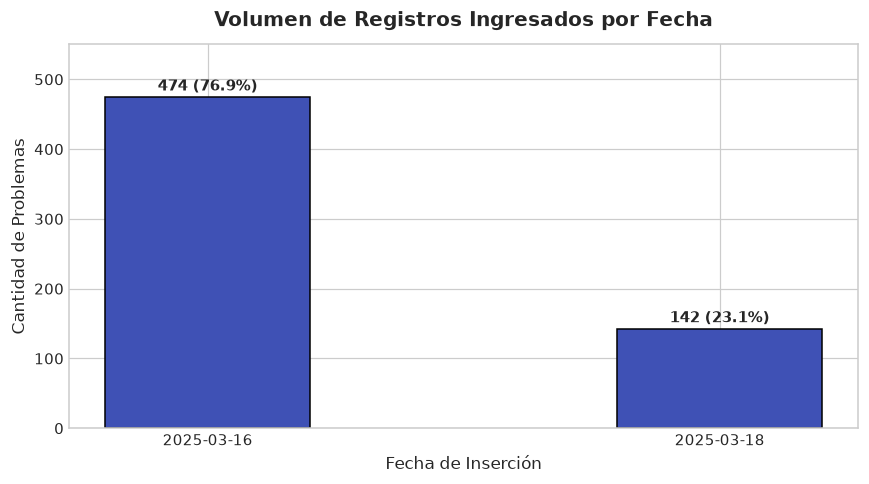

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
fechas_str = [d.strftime('%Y-%m-%d') for d in lotes.index]
bars = ax.bar(fechas_str, lotes.values, color='#3f51b5', edgecolor='black', width=0.4)
ax.set_title('Volumen de Registros Ingresados por Fecha', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Fecha de Inserción', fontsize=11)
ax.set_ylabel('Cantidad de Problemas', fontsize=11)
ax.set_ylim(0, 550)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h + 10, f"{h} ({h/len(df)*100:.1f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


**Conclusiones de Auditoría Temporal:**
- **Invariabilidad:** En el **100% de los registros**, `created_at` es exactamente idéntico a `updated_at`. No existe historial de actualizaciones post-creación en esta base.
- **Ingesta por Lotes:** La base se alimentó en dos únicos días de marzo de 2025: el **16/03** (76.9% de los datos) y el **18/03** (23.1%). Esto evidencia un proceso de carga masiva (*batch load*).


## 4. Distribución del Nivel de Dificultad (`difficulty_level`)
Analizamos la proporción de ejercicios según su grado de complejidad: `Easy`, `Medium` y `Hard`.


In [7]:
diff_order = ['Easy', 'Medium', 'Hard']
diff_counts = df['difficulty_level'].value_counts().reindex(diff_order)
diff_df = pd.DataFrame({
    'Dificultad': diff_counts.index,
    'Frecuencia': diff_counts.values,
    'Porcentaje (%)': (diff_counts.values / len(df) * 100).round(2)
})
diff_df


,Dificultad,Frecuencia,Porcentaje (%)
0,Easy,183,29.71
1,Medium,193,31.33
2,Hard,240,38.96


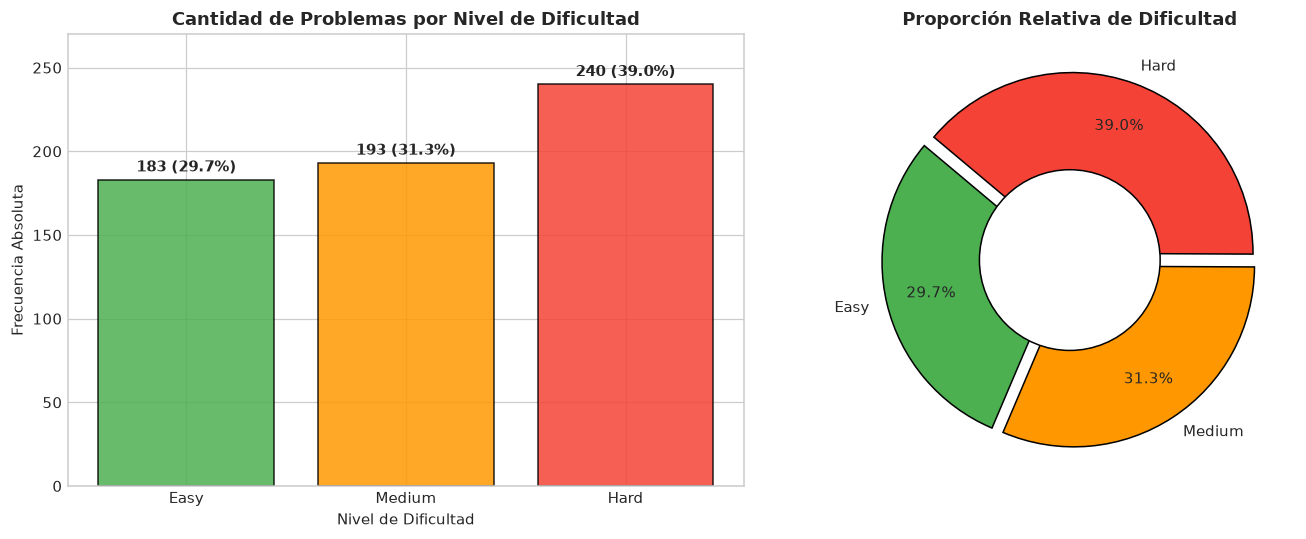

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colores = ['#4caf50', '#ff9800', '#f44336']

# Gráfico de barras
bars = ax1.bar(diff_order, diff_counts, color=colores, edgecolor='black', alpha=0.85)
ax1.set_title('Cantidad de Problemas por Nivel de Dificultad', fontsize=12, fontweight='bold')
ax1.set_xlabel('Nivel de Dificultad')
ax1.set_ylabel('Frecuencia Absoluta')
ax1.set_ylim(0, 270)
for i, v in enumerate(diff_counts):
    ax1.text(i, v + 5, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Gráfico Donut
ax2.pie(diff_counts, labels=diff_order, colors=colores, autopct='%1.1f%%', startangle=140,
        explode=(0.04, 0.04, 0.04), wedgeprops={'edgecolor': 'black'}, pctdistance=0.75)
centre_circle = plt.Circle((0, 0), 0.50, fc='white', edgecolor='black')
ax2.add_artist(centre_circle)
ax2.set_title('Proporción Relativa de Dificultad', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


**Conclusiones de Dificultad:**
- La categoría mayoritaria es **Hard** con **38.96%** (240 ejercicios).
- Le siguen **Medium** con **31.33%** (193 ejercicios) y **Easy** con **29.71%** (183 ejercicios).
- Este sesgo positivo hacia problemas de dificultad alta sugiere que la plataforma o repositorio de origen está orientada a evaluaciones técnicas avanzadas o competencias algorítmicas.


## 5. Análisis Textual de Enunciados y Tópicos Algorítmicos
Evaluamos la extensión de los enunciados y detectamos las estructuras de datos y paradigmas algorítmicos más frecuentes.


In [9]:
# Longitud de descripciones
df['desc_char_len'] = df['description'].astype(str).str.len()
df['desc_word_count'] = df['description'].astype(str).str.split().apply(len)

print("Estadísticas descriptivas de longitud de enunciado (palabras):")
print(df['desc_word_count'].describe().round(2))


Estadísticas descriptivas de longitud de enunciado (palabras):
count    616.00
mean      50.56
std       26.03
min       14.00
25%       32.00
50%       44.00
75%       61.25
max      235.00
Name: desc_word_count, dtype: float64


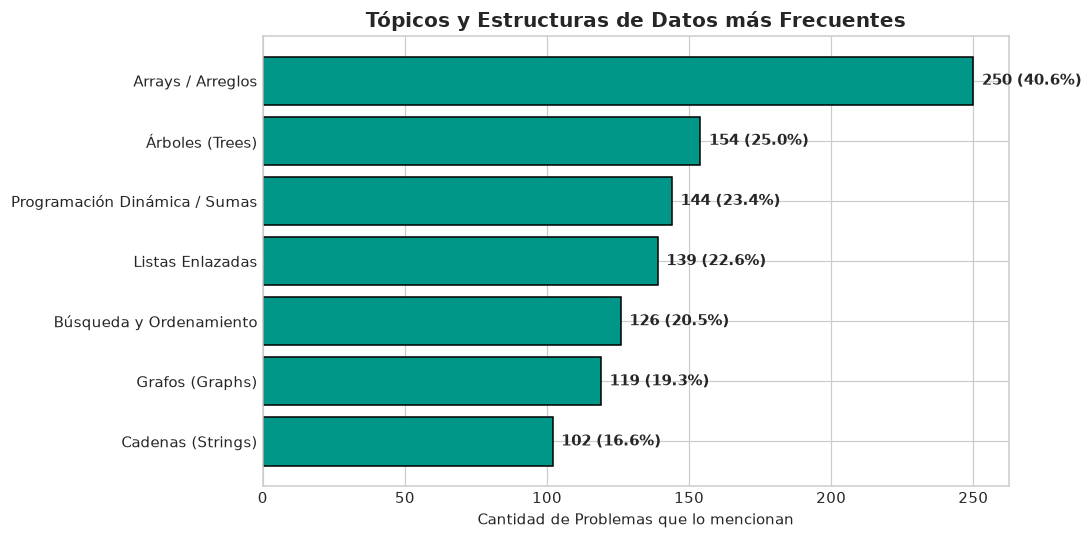

In [10]:
# Detección de tópicos por palabras clave
keywords = {
    "Arrays / Arreglos": ["array", "subarray", "vector"],
    "Árboles (Trees)": ["tree", "binary tree", "bst", "traversal"],
    "Programación Dinámica / Sumas": ["dynamic programming", "dp", "sum", "coins"],
    "Listas Enlazadas": ["list", "linked list"],
    "Búsqueda y Ordenamiento": ["sort", "search", "binary search"],
    "Grafos (Graphs)": ["graph", "edge", "cycle", "path"],
    "Cadenas (Strings)": ["string", "substring", "palindrome", "anagram"]
}

textos = (df['title'] + " " + df['description']).str.lower()
topicos_dict = {}
for topico, kw_list in keywords.items():
    pattern = "|".join(kw_list)
    topicos_dict[topico] = textos.str.contains(pattern, regex=True).sum()

topicos_s = pd.Series(topicos_dict).sort_values(ascending=True)

# Gráfico de Tópicos
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(topicos_s.index, topicos_s.values, color='#009688', edgecolor='black')
ax.set_title('Tópicos y Estructuras de Datos más Frecuentes', fontsize=13, fontweight='bold')
ax.set_xlabel('Cantidad de Problemas que lo mencionan')
for i, v in enumerate(topicos_s.values):
    ax.text(v + 3, i, f"{v} ({v/len(df)*100:.1f}%)", va='center', fontweight='bold')

plt.tight_layout()
plt.show()


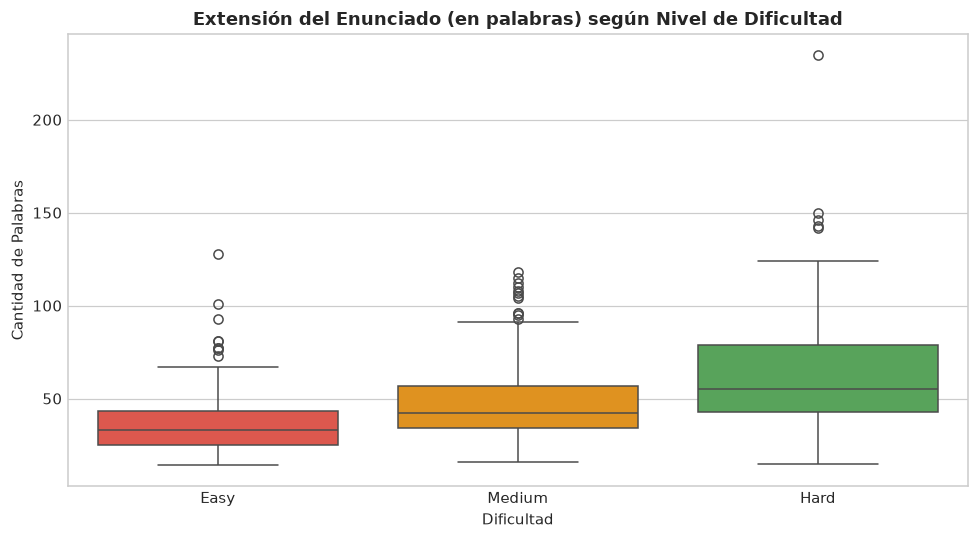

In [11]:
# Boxplot de extensión de descripción por dificultad
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x='difficulty_level', y='desc_word_count', order=diff_order,
            hue='difficulty_level', palette=colores, legend=False, ax=ax)
ax.set_title('Extensión del Enunciado (en palabras) según Nivel de Dificultad', fontsize=12, fontweight='bold')
ax.set_xlabel('Dificultad')
ax.set_ylabel('Cantidad de Palabras')
plt.tight_layout()
plt.show()


**Conclusiones Textuales y Temáticas:**
- **Arrays y Listas** representan más del 40% de los problemas, siendo la estructura de datos primordial.
- **Árboles (25%)** y **Grafos (~20%)** componen el núcleo de problemas avanzados de estructuras no lineales.
- Los problemas clasificados como **Hard** muestran una mayor dispersión y mediana en la longitud de palabras del enunciado en comparación con los ejercicios **Easy**.


## 6. Análisis de Campos Semi-Estructurados JSON (`examples`, `constraints`, `test_cases`)
En el archivo CSV original, estas tres columnas contienen texto codificado en formato JSON.  
Desde la perspectiva de diseño de bases de datos relacionales, esto representa un **antipatrón que viola la Primera Forma Normal (1FN)** (atributos no atómicos).  
Verificamos su validez sintáctica y cuantificamos su cardinalidad.


In [12]:
def parse_json_safely(val):
    try:
        parsed = json.loads(val)
        return len(parsed) if isinstance(parsed, list) else 0
    except Exception:
        return -1

df['cant_examples'] = df['examples'].apply(parse_json_safely)
df['cant_constraints'] = df['constraints'].apply(parse_json_safely)
df['cant_test_cases'] = df['test_cases'].apply(parse_json_safely)

# Validación de sintaxis
errores_json = (df[['cant_examples', 'cant_constraints', 'cant_test_cases']] == -1).sum().sum()
print(f"Total de registros con errores de sintaxis JSON: {errores_json} (100% de JSON válidos)\n")

json_stats = pd.DataFrame({
    'Columna JSON': ['examples', 'constraints', 'test_cases'],
    'Mínimo': [df['cant_examples'].min(), df['cant_constraints'].min(), df['cant_test_cases'].min()],
    'Promedio': [df['cant_examples'].mean().round(2), df['cant_constraints'].mean().round(2), df['cant_test_cases'].mean().round(2)],
    'Mediana': [df['cant_examples'].median(), df['cant_constraints'].median(), df['cant_test_cases'].median()],
    'Moda': [df['cant_examples'].mode()[0], df['cant_constraints'].mode()[0], df['cant_test_cases'].mode()[0]],
    'Máximo': [df['cant_examples'].max(), df['cant_constraints'].max(), df['cant_test_cases'].max()]
})
json_stats


Total de registros con errores de sintaxis JSON: 0 (100% de JSON válidos)



,Columna JSON,Mínimo,Promedio,Mediana,Moda,Máximo
0,examples,2,2.02,2.0,2,5
1,constraints,1,3.22,3.0,3,10
2,test_cases,5,5.32,5.0,5,32


In [13]:
# Detección de Valores Atípicos (Outliers)
outlier_tc = df[df['cant_test_cases'] > 15][['id', 'title', 'difficulty_level', 'cant_test_cases']]
print("Problemas con cantidad atípica de Casos de Prueba (test_cases > 15):")
outlier_tc


Problemas con cantidad atípica de Casos de Prueba (test_cases > 15):


,id,title,difficulty_level,cant_test_cases
11,122,Sum of Powers of Primes,Hard,32


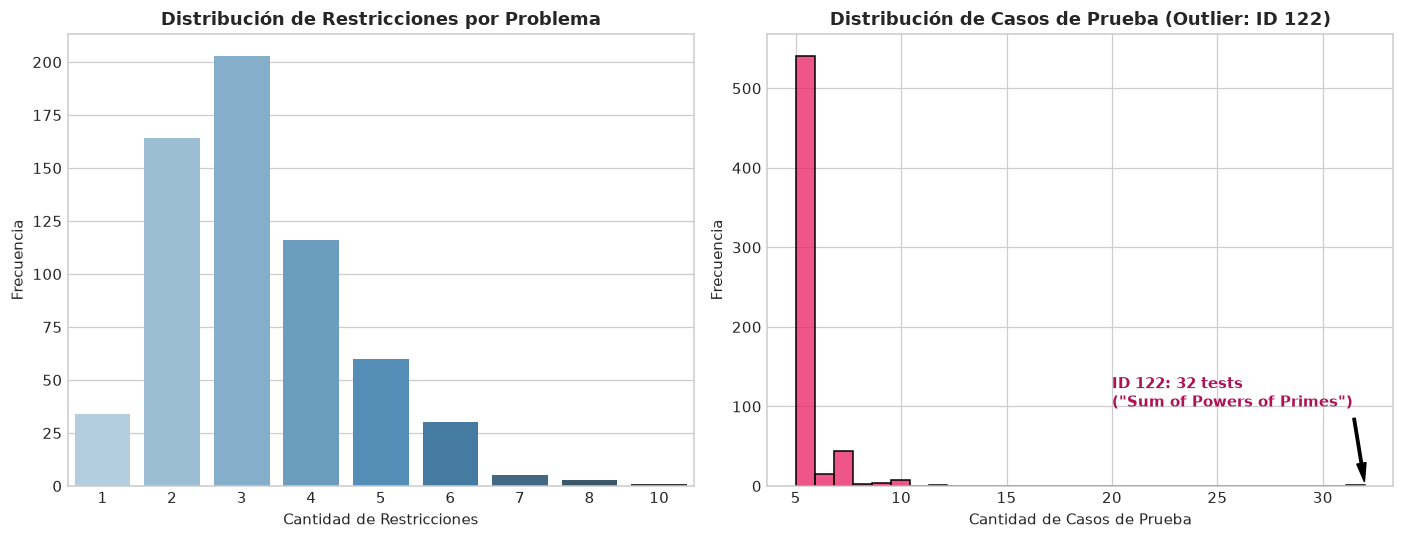

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Restricciones
sns.countplot(data=df, x='cant_constraints', hue='cant_constraints', palette='Blues_d', legend=False, ax=ax1)
ax1.set_title('Distribución de Restricciones por Problema', fontsize=12, fontweight='bold')
ax1.set_xlabel('Cantidad de Restricciones')
ax1.set_ylabel('Frecuencia')

# Test cases con llamada al outlier
sns.histplot(df['cant_test_cases'], bins=30, color='#e91e63', kde=False, ax=ax2)
ax2.set_title('Distribución de Casos de Prueba (Outlier: ID 122)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Cantidad de Casos de Prueba')
ax2.set_ylabel('Frecuencia')
ax2.annotate('ID 122: 32 tests\n("Sum of Powers of Primes")', xy=(32, 1), xytext=(20, 100),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             fontweight='bold', color='#ad1457')

plt.tight_layout()
plt.show()


**Conclusiones sobre Campos Semi-Estructurados:**
- **examples:** El 98.7% de los problemas cuenta con exactamente 2 ejemplos ilustrativos.
- **constraints:** La mayoría posee entre 2 y 4 restricciones matemáticas/operativas (promedio: 3.22).
- **test_cases:** El 87.8% (541 problemas) incluye exactamente 5 casos de prueba. Sin embargo, destaca un **outlier extremo**: el problema **ID 122 (*Sum of Powers of Primes*) con 32 casos de prueba**, sextuplicando la media.


## 7. Análisis Crítico de Integridad: Colisión de Títulos y Duplicados
Investigamos si la columna `title` posee unicidad o si existen colisiones de nombres y registros duplicados.


In [15]:
duplicados_titulos = df[df.duplicated(subset=['title'], keep=False)].sort_values('title')
titulos_repetidos_unicos = duplicados_titulos['title'].nunique()
total_filas_afectadas = len(duplicados_titulos)

print(f"Cantidad de títulos que se repiten: {titulos_repetidos_unicos}")
print(f"Total de registros afectados: {total_filas_afectadas}\n")

dups_exactos = []
dups_diferente_desc = []
dups_diferente_diff = []

for titulo, grupo in duplicados_titulos.groupby('title'):
    r1 = grupo.iloc[0]
    r2 = grupo.iloc[1]
    
    misma_desc = r1['description'] == r2['description']
    misma_diff = r1['difficulty_level'] == r2['difficulty_level']
    mismos_tests = r1['test_cases'] == r2['test_cases']
    
    if misma_desc and misma_diff and mismos_tests:
        dups_exactos.append((titulo, r1['id'], r2['id']))
    elif not misma_desc:
        dups_diferente_desc.append((titulo, r1['id'], r2['id']))
        
    if not misma_diff:
        dups_diferente_diff.append((titulo, r1['id'], r2['id'], r1['difficulty_level'], r2['difficulty_level']))

print(f"1. Casos 100% idénticos en contenido (Redundancia pura): {len(dups_exactos)}")
print(f"2. Casos con mismo título pero ENUNCIADOS DIFERENTES (Ambigüedad): {len(dups_diferente_desc)}")
print(f"3. Casos con cambio de nivel de dificultad para el mismo título: {len(dups_diferente_diff)}")


Cantidad de títulos que se repiten: 55
Total de registros afectados: 110



1. Casos 100% idénticos en contenido (Redundancia pura): 3
2. Casos con mismo título pero ENUNCIADOS DIFERENTES (Ambigüedad): 47
3. Casos con cambio de nivel de dificultad para el mismo título: 2


In [16]:
# Ejemplo de duplicado exacto
print("Ejemplo de duplicado idéntico:")
print(df[df['id'].isin([1, 290])][['id', 'title', 'difficulty_level', 'created_at']])

# Ejemplo de título idéntico pero problemas distintos
print("\nEjemplo de mismo título pero problemas conceptualmente distintos (ID 2 vs ID 99):")
p1 = df[df['id'] == 2].iloc[0]
p2 = df[df['id'] == 99].iloc[0]
print(f"- ID {p1['id']} (Title: {p1['title']}):\n  Enunciado: {p1['description'][:110]}...")
print(f"- ID {p2['id']} (Title: {p2['title']}):\n  Enunciado: {p2['description'][:110]}...")


Ejemplo de duplicado idéntico:
      id                          title difficulty_level  \
0      1  Maximum Path Sum with K Jumps             Hard   
295  290  Maximum Path Sum with K Jumps             Hard   

                          created_at  
0   2025-03-16 09:50:40.463489+00:00  
295 2025-03-16 17:54:16.425878+00:00  

Ejemplo de mismo título pero problemas conceptualmente distintos (ID 2 vs ID 99):
- ID 2 (Title: Same Tree Traversal):
  Enunciado: Given the pre-order and in-order traversals of a binary tree, determine if the given post-order traversal is v...
- ID 99 (Title: Same Tree Traversal):
  Enunciado: Given the root nodes of two binary trees, root1 and root2, determine if their inorder traversals are identical...


**Hallazgo Crítico:**
1. De los 55 títulos repetidos, **47 son problemas distintos con el mismo nombre**. Esto representa una falta de especificidad en la asignación de títulos (ambigüedad semántica).
2. Solo **3 pares son duplicados puros** (por ejemplo ID 1 y ID 290, ID 4 y ID 348).
3. **Implicación en Diseño de Bases de Datos:** La columna `title` **NO debe definirse con restricción de unicidad (`UNIQUE`)** en el modelo físico relacional a menos que previamente se normalicen y desambigüen los nombres de los ejercicios.


## 8. Conclusiones Integrales y Recomendaciones para Diseño de Base de Datos

### Resumen Ejecutivo de Hallazgos
1. **Completitud e Integridad Referencial Primaria:**
   - La tabla presenta una completitud del 100% (cero valores nulos o campos vacíos).
   - El atributo `id` cumple con todas las propiedades de una clave primaria artificial (`PRIMARY KEY AUTOINCREMENT`): es entero, estrictamente creciente (1 a 616) y único.
2. **Normalización (Violación de la 1FN):**
   - Las columnas `examples`, `constraints` y `test_cases` rompen la Primera Forma Normal al almacenar listas y diccionarios serializados en JSON.
   - En una arquitectura relacional, estas estructuras deben desacoplarse en tablas subordinadas:
     - `question_examples (id, question_id, input_data, output_data)`
     - `question_constraints (id, question_id, constraint_text)`
     - `question_test_cases (id, question_id, input_data, expected_output)`
3. **Tratamiento de Claves Alternativas (`UNIQUE`):**
   - No se debe imponer una restricción `UNIQUE` sobre la columna `title`, dado que se verificaron 47 problemas distintos que comparten idéntico nombre.
4. **Auditoría y Desnormalización Temporal:**
   - La columna `updated_at` es 100% redundante con `created_at` en el estado actual de los datos. Para optimizar almacenamiento en un Data Warehouse, puede descartarse o reemplazarse por una tabla de auditoría / eventos de actualización mediante disparadores (*triggers*).
5. **Valores Atípicos (Outliers):**
   - Se debe contemplar un diseño de almacenamiento variable (tipo `TEXT` o particionamiento) para casos extremos de verificación como el ID 122 con 32 casos de prueba, frente a los 5 casos habituales.
